In [1]:
import torch
from torchvision import datasets
from torchvision.transforms import ToTensor
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
import pathlib
from torchvision.datasets import ImageFolder
from torchvision.transforms import Compose, Resize, ToTensor
from torch.utils.data import Subset

In [2]:
pathToModels = pathlib.Path("models")
pathToData = pathlib.Path("data")
BATCH_SIZE = 64
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TRASNFORM = Compose([
    Resize((224, 224)),
    ToTensor()
])

In [3]:
trainDataset = ImageFolder(
    root=pathToData / 'dogsVsCats/train',
    transform=TRASNFORM
)
testDataset = ImageFolder(
    root=pathToData / 'dogsVsCats/test',
    transform=TRASNFORM
)
trainDataset = Subset(trainDataset, 
                      list(range(0, 2000)) + list(range(12500, 14500)))
testDataset = Subset(testDataset, 
                     list(range(0, 1000)) + list(range(2500, 3500)))
trainLoader = torch.utils.data.DataLoader(
    trainDataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)
testLoader = torch.utils.data.DataLoader(
    testDataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [6]:
trainDataset[0][0].shape

torch.Size([3, 224, 224])

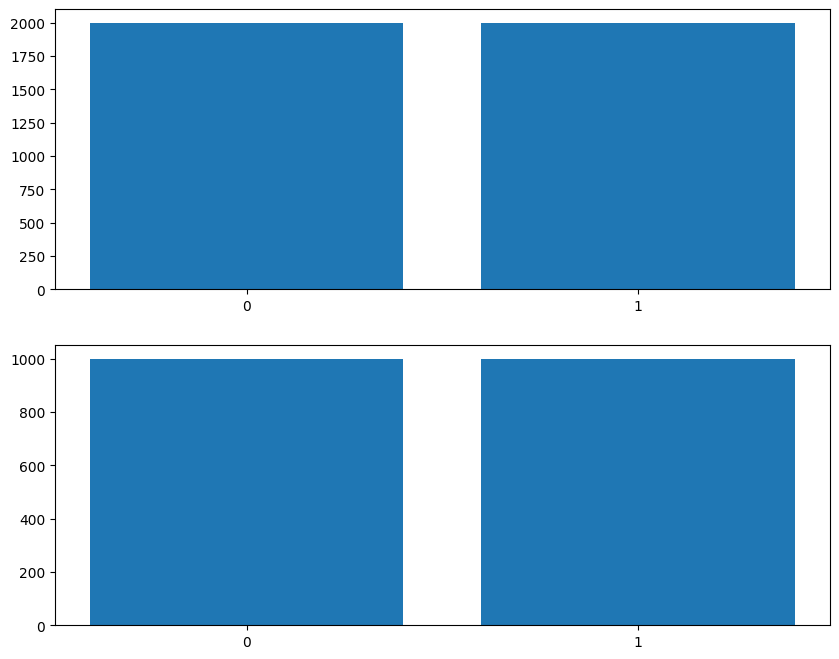

In [4]:
fig, axs = plt.subplots(2, 1, figsize=(10, 8)) 

trainCounts = np.bincount([y for _, y in trainDataset])
axs[0].bar(range(len(trainCounts)), trainCounts)
axs[0].set_xticks(range(len(trainCounts)))

testCounts = np.bincount([y for _, y in testDataset])
axs[1].bar(range(len(testCounts)), testCounts)
axs[1].set_xticks(range(len(testCounts)))

plt.show()

In [5]:
from utils import *


In [6]:
class dogsVsCatsModel(nn.Module):
    def __init__(self):
        super(dogsVsCatsModel, self).__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
        self.fc1 = nn.Linear(64 * 28 * 28, 256)
        self.fc2 = nn.Linear(256, 2)
        self.dropout = nn.Dropout(0.4)

    def forward(self, x):
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)
        x = self.conv2(x)
        x = self.relu(x)
        x = self.pool(x)
        x = self.conv3(x)
        x = self.relu(x)
        x = self.pool(x)
        x = x.view(-1, 64 * 28 * 28)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return x

In [7]:
model = dogsVsCatsModel().to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
model = train(model, trainLoader, testLoader, optimizer, criterion, DEVICE, 5, 'dogsVsCats')

Epoch 1/5 - Train Loss: 0.0111, Train Accuracy: 0.5443 - Test Loss: 0.0108, Test Accuracy: 0.5615
Epoch 2/5 - Train Loss: 0.0102, Train Accuracy: 0.6360 - Test Loss: 0.0101, Test Accuracy: 0.6590
Epoch 3/5 - Train Loss: 0.0093, Train Accuracy: 0.6977 - Test Loss: 0.0096, Test Accuracy: 0.6790
Epoch 4/5 - Train Loss: 0.0083, Train Accuracy: 0.7312 - Test Loss: 0.0091, Test Accuracy: 0.6975
Epoch 5/5 - Train Loss: 0.0082, Train Accuracy: 0.7455 - Test Loss: 0.0095, Test Accuracy: 0.6785


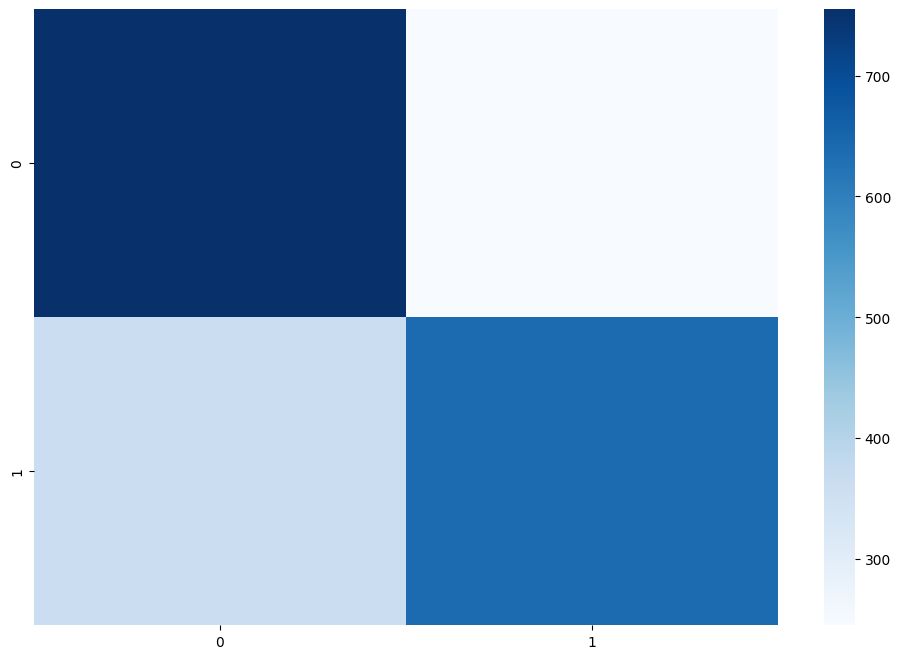

In [8]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
y_true = []
y_pred = []
model.eval()
with torch.no_grad():
    for images, labels in testLoader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 8))
sns.heatmap(cm, cmap='Blues')
    
plt.show()